# 05: Modelling

**Goal:** predict hourly rideshare fare at JFK from demand conditions (flight
volume, arrival delay, time of day, day of week). If a model can tell a driver
when rideshare is likely to cost more than the $70 flat fare, that's a direct,
practical answer to the research question 

This notebook works on `data/curated/jfk_hourly_demand.parquet` (4,124 rows) -
small enough for plain `pandas`/`scikit-learn`, no Spark needed here.

Two contrasting models: a linear regression (interpretable, coefficients show
which conditions push rideshare price up or down) and a random forest
(captures non-linearities/interactions, usually more accurate but less
directly interpretable). Temporal split: train Jan-Apr 2025, test May-Jun
2025 -- no random shuffling, since predicting the future from the past is the
actual use case.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

jfk_hourly = pd.read_parquet("../data/curated/jfk_hourly_demand.parquet")
print(f"Rows: {len(jfk_hourly):,}")
jfk_hourly.head()

Rows: 4,124


,pickup_hour,n_flights,avg_arr_delay_min,n_yellow_pickups,n_flat_fare_pickups,avg_yellow_fare,avg_flat_fare,avg_metered_fare,n_hvfhv_pickups,avg_hvfhv_fare
0,2025-01-01 01:00:00,4,29.25,59.0,13.0,51.700000,70.0,45.302273,151.0,58.856954
1,2025-01-01 05:00:00,5,0.00,77.0,18.0,50.358442,70.0,43.262500,169.0,51.538225
2,2025-01-01 06:00:00,5,0.00,141.0,47.0,55.039645,70.0,42.601220,262.0,58.509885
3,2025-01-01 07:00:00,6,0.50,112.0,50.0,60.086607,70.0,50.129310,295.0,61.769627
4,2025-01-01 08:00:00,10,5.30,89.0,37.0,56.960674,70.0,47.590000,215.0,59.938698


## Feature engineering

Input attributes: `n_flights` and `avg_arr_delay_min`
, plus `hour_of_day` and `day_of_week` 

Output attribute: `avg_hvfhv_fare` (continuous) - the hourly average rideshare
fare at JFK.

In [2]:
# Drop the row with no rideshare fare recorded that hour (can't predict what wasn't observed).
n_before = len(jfk_hourly)
jfk_hourly = jfk_hourly.dropna(subset=["avg_hvfhv_fare"])
print(f"Dropped {n_before - len(jfk_hourly)} row(s) with no avg_hvfhv_fare")

jfk_hourly["hour_of_day"] = jfk_hourly["pickup_hour"].dt.hour
jfk_hourly["day_of_week"] = jfk_hourly["pickup_hour"].dt.dayofweek  # 0 = Monday

features = pd.get_dummies(
    jfk_hourly[["n_flights", "avg_arr_delay_min", "hour_of_day", "day_of_week"]],
    columns=["hour_of_day", "day_of_week"],
    drop_first=True,
)
target = jfk_hourly["avg_hvfhv_fare"]

print(f"Feature matrix: {features.shape}")
features.head()

Dropped 1 row(s) with no avg_hvfhv_fare
Feature matrix: (4123, 31)


,n_flights,avg_arr_delay_min,hour_of_day_1,hour_of_day_2,hour_of_day_3,hour_of_day_4,hour_of_day_5,hour_of_day_6,hour_of_day_7,hour_of_day_8,...,hour_of_day_20,hour_of_day_21,hour_of_day_22,hour_of_day_23,day_of_week_1,day_of_week_2,day_of_week_3,day_of_week_4,day_of_week_5,day_of_week_6
0,4,29.25,True,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False
1,5,0.00,False,False,False,False,True,False,False,False,...,False,False,False,False,False,True,False,False,False,False
2,5,0.00,False,False,False,False,False,True,False,False,...,False,False,False,False,False,True,False,False,False,False
3,6,0.50,False,False,False,False,False,False,True,False,...,False,False,False,False,False,True,False,False,False,False
4,10,5.30,False,False,False,False,False,False,False,True,...,False,False,False,False,False,True,False,False,False,False


In [3]:
## Temporal train/test split: train Jan-Apr 2025, test May-Jun 2025.
# No random shuffling -- the model should predict the future from the past,
# same as a driver actually using it would.
train_mask = jfk_hourly["pickup_hour"] < "2025-05-01"

X_train, X_test = features[train_mask], features[~train_mask]
y_train, y_test = target[train_mask], target[~train_mask]

print(f"Train: {len(X_train):,} hours (Jan-Apr)")
print(f"Test:  {len(X_test):,} hours (May-Jun)")

Train: 2,721 hours (Jan-Apr)
Test:  1,402 hours (May-Jun)


## Model 1: Linear regression



In [4]:
def evaluate(y_true, y_pred, name):
    """Compute MAE, RMSE, and R^2 for a set of predictions, as a single row dict."""
    mae = mean_absolute_error(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    r2 = r2_score(y_true, y_pred)
    return {"model": name, "MAE ($)": mae, "RMSE ($)": rmse, "R2": r2}


linreg = LinearRegression()
linreg.fit(X_train, y_train)
linreg_pred = linreg.predict(X_test)

linreg_metrics = evaluate(y_test, linreg_pred, "Linear regression")
linreg_metrics

{'model': 'Linear regression',
 'MAE ($)': 6.60728402492219,
 'RMSE ($)': 8.27244364983688,
 'R2': 0.5783859400598375}

In [5]:
# Top coefficients by absolute size -- which conditions push rideshare fare
# up or down the most, holding everything else fixed.
coefs = (
    pd.Series(linreg.coef_, index=X_train.columns)
    .sort_values(key=abs, ascending=False)
)
coefs.head(10)

hour_of_day_3    -20.081581
hour_of_day_16    16.859712
hour_of_day_15    15.949793
hour_of_day_4    -15.097513
hour_of_day_2    -14.083333
hour_of_day_17    13.722814
hour_of_day_14    13.669381
hour_of_day_7     11.779235
hour_of_day_18    10.040730
hour_of_day_13     7.785221
dtype: float64

## Model 2: Random forest

A tree ensemble can capture non-linear effects and interactions the linear
model can't (e.g. flight volume might matter more during evening rush hour than
at 3am), usually at the cost of direct interpretability.

In [6]:
rf = RandomForestRegressor(n_estimators=200, max_depth=8, random_state=0)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

rf_metrics = evaluate(y_test, rf_pred, "Random forest")
rf_metrics

{'model': 'Random forest',
 'MAE ($)': 7.013636433934708,
 'RMSE ($)': 8.76287288751002,
 'R2': 0.5269135883231635}

In [7]:
feature_importance = (
    pd.Series(rf.feature_importances_, index=X_train.columns)
    .sort_values(ascending=False)
)
feature_importance.head(10)

n_flights            0.521076
avg_arr_delay_min    0.078901
hour_of_day_15       0.060046
hour_of_day_16       0.057275
hour_of_day_1        0.054199
hour_of_day_6        0.037658
hour_of_day_17       0.030645
hour_of_day_14       0.027730
hour_of_day_5        0.020162
hour_of_day_3        0.016609
dtype: float64

## Comparing the two models

In [8]:
metrics_comparison = pd.DataFrame([linreg_metrics, rf_metrics])
metrics_comparison

,model,MAE ($),RMSE ($),R2
0,Linear regression,6.607284,8.272444,0.578386
1,Random forest,7.013636,8.762873,0.526914


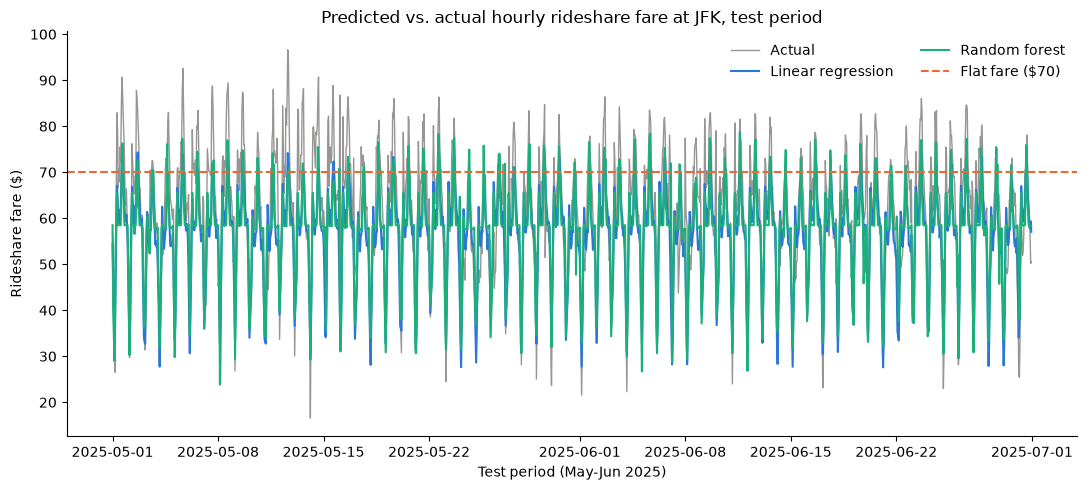

In [9]:
test_hours = jfk_hourly.loc[~train_mask, "pickup_hour"]

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(test_hours, y_test.values, color="#52514e", linewidth=1, alpha=0.6, label="Actual")
ax.plot(test_hours, linreg_pred, color="#2a78d6", linewidth=1.5, label="Linear regression")
ax.plot(test_hours, rf_pred, color="#1baf7a", linewidth=1.5, label="Random forest")
ax.axhline(70, color="#eb6834", linestyle="--", linewidth=1.5, label="Flat fare ($70)")

ax.set_ylabel("Rideshare fare ($)")
ax.set_xlabel("Test period (May-Jun 2025)")
ax.set_title("Predicted vs. actual hourly rideshare fare at JFK, test period")
ax.legend(frameon=False, ncol=2)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../plots/jfk_fare_prediction.png", dpi=150)
plt.show()

## When does the flat fare actually beat rideshare?

 what share of hours does rideshare cost more
than the $70 flat fare, by hour of day?

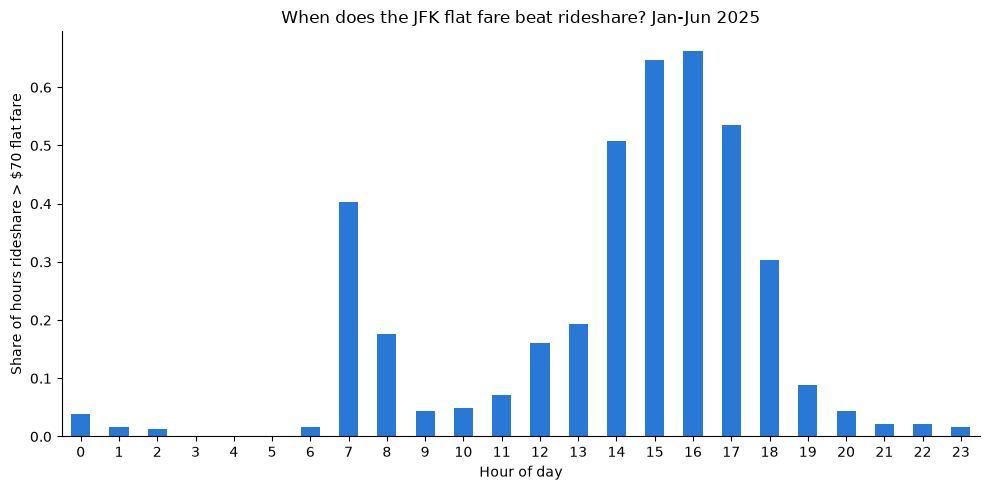

In [10]:
jfk_hourly["flat_fare_wins"] = jfk_hourly["avg_hvfhv_fare"] > 70
hourly_advantage = jfk_hourly.groupby("hour_of_day")["flat_fare_wins"].mean()

fig, ax = plt.subplots(figsize=(10, 5))
hourly_advantage.plot(kind="bar", ax=ax, color="#2a78d6")
ax.set_ylabel("Share of hours rideshare > $70 flat fare")
ax.set_xlabel("Hour of day")
ax.set_title("When does the JFK flat fare beat rideshare? Jan-Jun 2025")
ax.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../plots/jfk_flat_fare_advantage_by_hour.png", dpi=150)
plt.show()